# Notebook 05 — Cooperative GPU Tiling & Threadgroup Memory (Apple M5)

**Goal:** understand why FlashAttention needs *cooperation*, not just smaller tiles. We will (1) build a CPU reference, (2) visualize data reuse and the shared-memory budget, (3) simulate cooperative loads, (4) implement a tiled online-softmax attention algorithm, and (5) optionally launch a tiny **custom MLX Metal kernel** that shares a key tile between threads.

**Important scope:** The GPU kernel here computes *tiled QK scores to demonstrate threadgroup cooperation*. It is **not yet a fused FlashAttention GPU kernel**, and it intentionally writes a score matrix for testing. The NumPy implementation is the full streaming attention algorithm. Moving the online softmax and output accumulator into a cooperative GPU kernel is our next milestone.

This notebook runs end-to-end without MLX on any Python with NumPy and Matplotlib. Metal sections are guarded and only run when MLX works on your Mac.

References: [MLX custom Metal kernels](https://ml-explore.github.io/mlx/build/html/dev/custom_metal_kernels.html), [MLX API](https://ml-explore.github.io/mlx/build/html/python/_autosummary/mlx.core.fast.metal_kernel.html), [FlashAttention paper](https://arxiv.org/abs/2205.14135).

## 0. Environment and prerequisites

A prior notebook reported `No module named mlx`. That typically indicates an interpreter mismatch. The CPU portion below needs only `numpy` and `matplotlib`.

If needed, run `%pip install -U mlx` **in this notebook**, restart the kernel, and repeat the diagnostic cell. It is fine to continue CPU sections first.

In [1]:
import sys, platform, importlib.util
import numpy as np
import matplotlib.pyplot as plt

print('Python executable:', sys.executable)
print('Platform:', platform.platform())
print('Architecture:', platform.machine())
print('NumPy:', np.__version__)
print('MLX importable:', importlib.util.find_spec('mlx') is not None)

try:
    import mlx.core as mx
    MLX_OK = bool(mx.is_available(mx.gpu))
    print('MLX GPU available:', MLX_OK)
except Exception as exc:
    MLX_OK = False
    print('MLX unavailable:', repr(exc))
    print('To install into this kernel: %pip install -U mlx; then RESTART the kernel.')

Python executable: /Users/quangphuoc/Desktop/Personal Projects/vlm_with_tools copy/.venv/bin/python
Platform: macOS-27.0.1-arm64-arm-64bit
Architecture: arm64
NumPy: 2.5.4
MLX importable: True
MLX GPU available: True


## 1. Why tiling is not enough

For $Q,K\in\mathbb R^{N\times d}$ and $V\in\mathbb R^{N\times d_v}$,

$$O=\operatorname{softmax}(QK^\top/\sqrt d)V.$$

A single thread per query row can stream over keys, but neighboring query threads repeatedly load the **same** $K$ and $V$. In a cooperative kernel, a *threadgroup* loads a $B_K\times d$ key tile (and optionally a value tile) into **threadgroup memory**, synchronizes, then multiple threads reuse that tile for different queries.

On Apple Silicon, CPU and GPU share a unified physical memory system, but on-chip threadgroup memory and caches are still distinct resources with different access costs. Do not equate unified memory with zero memory traffic.

Memory footprint for one tile (in bytes):

$$M_{\rm tile}=s\,[B_Qd+B_Kd+B_Kd_v+B_QB_K]+s_a\,[B_Qd_v+2B_Q],$$

where $s$ is the input/score element size and $s_a$ the accumulator size. This is a **conceptual upper-bound staging model**, not an exact prediction of a particular compiler's register or threadgroup allocation.

In [2]:
# Modify these to see reuse and capacity trade-offs.
N, d, dv = 128, 32, 32
BQ, BK = 16, 16
bytes_input, bytes_acc = 4, 4

staging_bytes = bytes_input * (BQ*d + BK*d + BK*dv + BQ*BK) + bytes_acc * (BQ*dv + 2*BQ)
print(f'Illustrative staging footprint: {staging_bytes:,} bytes ({staging_bytes/1024:.1f} KiB)')
print(f'Key tile reused across up to {BQ} query rows per query tile.')

Illustrative staging footprint: 9,344 bytes (9.1 KiB)
Key tile reused across up to 16 query rows per query tile.


## 2. Visualize the tile schedule

Each grid cell is a score tile $S_{ij}=Q_iK_j^\top$. The same $K_j,V_j$ tile can serve every query row within $Q_i$ once staged. The heatmap indicates the traversal order rather than runtime measurements.

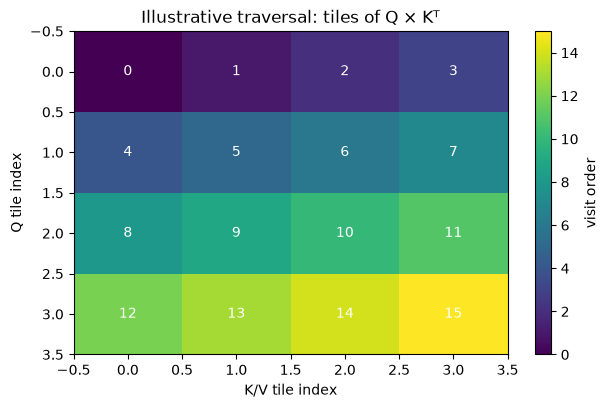

In [3]:
def plot_tile_schedule(nq=64, nk=64, bq=16, bk=16):
    qblocks = (nq+bq-1)//bq
    kblocks = (nk+bk-1)//bk
    schedule = np.arange(qblocks*kblocks).reshape(qblocks, kblocks)
    fig, ax = plt.subplots(figsize=(7,4.2))
    image = ax.imshow(schedule, cmap='viridis', aspect='auto')
    for i in range(qblocks):
        for j in range(kblocks):
            ax.text(j,i,f'{schedule[i,j]}',ha='center',va='center',color='white',fontsize=10)
    ax.set(xlabel='K/V tile index', ylabel='Q tile index', title='Illustrative traversal: tiles of Q × Kᵀ')
    fig.colorbar(image,ax=ax,label='visit order')
    plt.show()
plot_tile_schedule()

## 3. Threadgroup cooperation (conceptual)

For one $(Q_i,K_j)$ tile, threads cooperate:

1. Each thread loads a subset of $K_j$ from device memory into a shared tile.
2. **Barrier:** all writes to threadgroup memory must complete before any thread reads the complete tile.
3. Several query threads consume the shared keys.
4. **Barrier before reuse:** make sure readers are done before overwriting the buffer with another key tile.

A barrier does not automatically make every access race-free; keep all threads in the workgroup following compatible control flow around barriers.

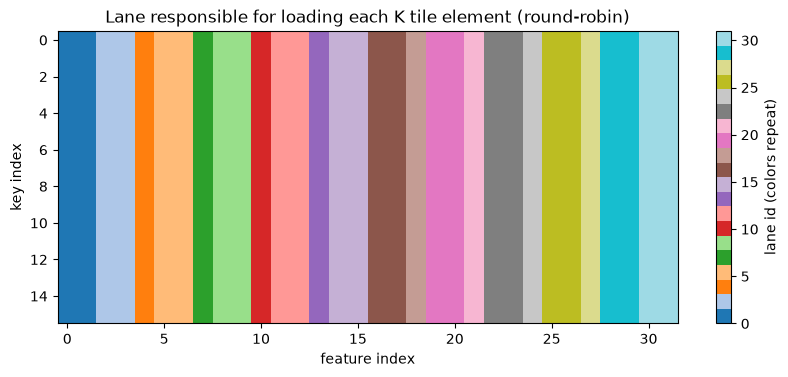

Each lane loads 16 elements in this example.


In [4]:
# Plot how one 16 x 32 key tile can be loaded by 32 cooperative lanes.
BK_DEMO, D_DEMO, LANES = 16, 32, 32
owner = np.arange(BK_DEMO*D_DEMO).reshape(BK_DEMO,D_DEMO) % LANES
fig, ax = plt.subplots(figsize=(10,3.8))
img = ax.imshow(owner,cmap='tab20',aspect='auto',interpolation='nearest')
ax.set(title='Lane responsible for loading each K tile element (round-robin)',xlabel='feature index',ylabel='key index')
fig.colorbar(img,ax=ax,label='lane id (colors repeat)')
plt.show()
print('Each lane loads',BK_DEMO*D_DEMO//LANES,'elements in this example.')

## 4. Build the dense reference

We'll use FP64 for the CPU reference to make correctness differences easier to interpret.

In [5]:
def dense_attention(q, k, v, causal=False):
    q, k, v = map(np.asarray, (q,k,v))
    assert q.ndim == k.ndim == v.ndim == 2
    assert q.shape[1] == k.shape[1] and k.shape[0] == v.shape[0]
    s = (q @ k.T) / np.sqrt(q.shape[1])
    if causal:
        assert q.shape[0] == k.shape[0], 'Causal self-attention requires equal Q/K lengths here'
        s = np.where(np.arange(k.shape[0])[None,:] <= np.arange(q.shape[0])[:,None], s, -np.inf)
    m = np.max(s, axis=1, keepdims=True)
    p = np.exp(s - m)
    p /= np.sum(p, axis=1, keepdims=True)
    return p @ v

rng = np.random.default_rng(7)
q = rng.normal(size=(33, 16))
k = rng.normal(size=(33, 16))
v = rng.normal(size=(33, 12))
print('Dense output:', dense_attention(q,k,v).shape)

Dense output: (33, 12)


## 5. Cooperative tiled attention — CPU mathematical model

For a query tile, maintain a row-wise max $m$, exponential sum $\ell$ and weighted numerator $a$. For a new score block $S$:

$$m' = \max(m,\operatorname{rowmax}(S))$$
$$\alpha=e^{m-m'}, \quad P=e^{S-m'[:,None]}$$
$$\ell'=\alpha\ell+\operatorname{rowsum}(P)$$
$$a'=\alpha[:,None]a+PV_j.$$

To handle entirely masked blocks, we explicitly use zero contributions rather than evaluating $-\infty-(-\infty)$. This version never materializes a full $N\times N$ score array.

In [6]:
def tiled_attention(q, k, v, bq=16, bk=16, causal=False, record=False):
    q, k, v = map(np.asarray, (q,k,v))
    nq,d = q.shape; nk = k.shape[0]; dv = v.shape[1]
    assert k.shape[1] == d and v.shape[0] == nk
    if causal:
        assert nq == nk, 'Causal self-attention only in this notebook'
    output = np.empty((nq,dv), dtype=np.float64)
    history = []
    scale = 1/np.sqrt(d)
    for qs in range(0,nq,bq):
        qe = min(qs+bq,nq)
        qi = q[qs:qe].astype(np.float64)
        m = np.full(qe-qs, -np.inf)
        ell = np.zeros(qe-qs)
        acc = np.zeros((qe-qs,dv))
        for ks in range(0,nk,bk):
            ke = min(ks+bk,nk)
            scores = qi @ k[ks:ke].T * scale
            if causal:
                keep = np.arange(ks,ke)[None,:] <= np.arange(qs,qe)[:,None]
                scores = np.where(keep,scores,-np.inf)
            blockmax = np.max(scores,axis=1)
            new_m = np.maximum(m,blockmax)
            # Valid rows: rows with at least one unmasked score so far.
            valid = np.isfinite(new_m)
            alpha = np.zeros_like(ell)
            alpha[valid] = np.exp(m[valid]-new_m[valid])
            probabilities = np.zeros_like(scores)
            probabilities[valid] = np.exp(scores[valid]-new_m[valid,None])
            ell = alpha*ell + probabilities.sum(axis=1)
            acc = alpha[:,None]*acc + probabilities @ v[ks:ke]
            m = new_m
            if record and qs == 0:
                history.append((ks, m.copy(),ell.copy(),acc.copy()))
        assert np.all(ell>0), 'Every query should have at least one visible key'
        output[qs:qe] = acc / ell[:,None]
    return (output,history) if record else output

for causal in [False, True]:
    expected = dense_attention(q,k,v,causal=causal)
    for bq,bk in [(1,1),(4,5),(8,8),(16,16),(64,64)]:
        got = tiled_attention(q,k,v,bq,bk,causal=causal)
        np.testing.assert_allclose(got,expected,rtol=1e-12,atol=1e-12)
    print(f'CPU tiled correctness, causal={causal}: PASS')

CPU tiled correctness, causal=False: PASS
CPU tiled correctness, causal=True: PASS


## 6. Visualize online-softmax state updates

For the first query in the first query tile, plot how the maximum and denominator evolve as key/value tiles arrive.

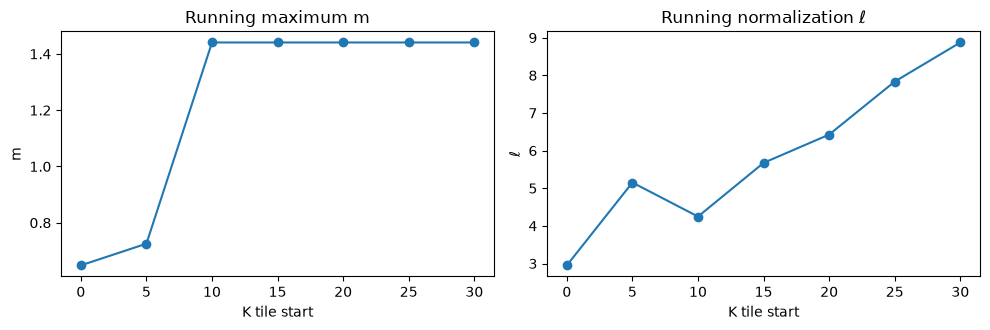

In [7]:
_, states = tiled_attention(q,k,v,bq=8,bk=5,record=True)
xs = [s[0] for s in states]
m_values = [s[1][0] for s in states]
l_values = [s[2][0] for s in states]
fig, axs = plt.subplots(1,2,figsize=(10,3.4))
axs[0].plot(xs,m_values,marker='o'); axs[0].set(title='Running maximum m',xlabel='K tile start',ylabel='m')
axs[1].plot(xs,l_values,marker='o'); axs[1].set(title='Running normalization ℓ',xlabel='K tile start',ylabel='ℓ')
plt.tight_layout(); plt.show()

## 7. Model key memory traffic, without claiming a speedup

A simplified **algorithmic load-count model**: an implementation that loads the same key vector for each query reads $N_qN_kd$ key elements. A cooperative tile that loads each key tile only once per query tile reads $\lceil N_q/B_Q\rceil N_kd$ key elements (assuming no cache reuse across groups). Real GPU performance also depends on caches, occupancy, registers, scheduling, and arithmetic throughput.

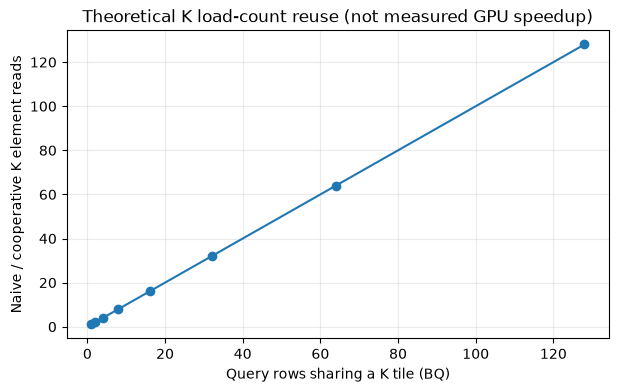

In [8]:
NQ, NK, D = 1024,1024,64
bqs = np.array([1,2,4,8,16,32,64,128])
naive_reads = NQ*NK*D
cooperative_reads = np.ceil(NQ/bqs).astype(int)*NK*D
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(bqs,naive_reads/cooperative_reads,'o-')
ax.set(title='Theoretical K load-count reuse (not measured GPU speedup)',xlabel='Query rows sharing a K tile (BQ)',ylabel='Naive / cooperative K element reads')
ax.grid(alpha=.25)
plt.show()

## 8. Optional Apple M5 GPU lab: one cooperative **QK tile kernel**

This is a focused learning kernel:

- Each Metal threadgroup is assigned one $16\times16$ score tile.
- All 32 lanes load a shared $16\times32$ key tile into `threadgroup` memory.
- A barrier protects consumers of that shared tile.
- The first 16 lanes compute one query row each.
- The kernel writes the complete score matrix *for inspection*.

**This is intentionally not yet a fused attention kernel.** It isolates cooperative staging and synchronization, making debugging practical before adding online softmax and V accumulation. Dimensions and dtype are fixed to FP32, $d=32$, and $N$ divisible by 16. GPU cells skip cleanly without MLX.

In [9]:
METAL_QK_SOURCE = r"""
    constexpr uint BQ = 16;
    constexpr uint BK = 16;
    constexpr uint D = 32;
    // Demo-only threadgroup storage: 16 key vectors x 32 features.
    threadgroup float shared_k[BK * D];
    uint lane = thread_index_in_threadgroup;
    uint3 tile = threadgroup_position_in_grid;
    uint qi0 = tile.y * BQ;
    uint kj0 = tile.x * BK;
    // Cooperative loading: 32 threads, 16 elements per thread.
    for (uint e = lane; e < BK * D; e += 32) {
        uint local_k = e / D;
        uint feature = e % D;
        shared_k[e] = k[(kj0 + local_k) * D + feature];
    }
    threadgroup_barrier(mem_flags::mem_threadgroup);
    // First 16 threads calculate 16 x 16 scores using shared K.
    if (lane < BQ) {
        uint qi = qi0 + lane;
        for (uint j = 0; j < BK; ++j) {
            float sum = 0.0f;
            for (uint feature = 0; feature < D; ++feature) {
                sum += q[qi * D + feature] * shared_k[j * D + feature];
            }
            scores[qi * N + (kj0 + j)] = sum * 0.1767766952966369f; // 1/sqrt(32)
        }
    }
"""

if MLX_OK:
    print('MLX GPU detected. Ready to compile demonstration kernel in the next cell.')
else:
    print('Skipping GPU lab: MLX unavailable in this kernel. CPU learning remains valid.')

MLX GPU detected. Ready to compile demonstration kernel in the next cell.


In [10]:
if MLX_OK:
    # Use a distinct name so the JIT compiler/cache can identify this example.
    qk_kernel = mx.fast.metal_kernel(
        name='fa05_cooperative_qk_tile_v1',
        input_names=['q','k'],
        output_names=['scores'],
        source=METAL_QK_SOURCE,
    )

    def qk_scores_cooperative(q_np, k_np):
        assert q_np.shape == k_np.shape
        n,d = q_np.shape
        assert d == 32 and n % 16 == 0
        q_mx = mx.array(np.ascontiguousarray(q_np,dtype=np.float32))
        k_mx = mx.array(np.ascontiguousarray(k_np,dtype=np.float32))
        # Grid is TOTAL THREADS in MLX, not number of threadgroups.
        # Here one threadgroup (32 lanes) per (Q tile, K tile).
        result = qk_kernel(
            inputs=[q_mx,k_mx],
            template=[('N',n)],
            grid=(32*(n//16),n//16,1),
            threadgroup=(32,1,1),
            output_shapes=[(n,n)],
            output_dtypes=[mx.float32],
        )[0]
        mx.eval(result)
        return np.array(result)

    q_demo = rng.normal(size=(32,32)).astype(np.float32)
    k_demo = rng.normal(size=(32,32)).astype(np.float32)
    computed = qk_scores_cooperative(q_demo,k_demo)
    reference = q_demo @ k_demo.T / np.sqrt(32.0)
    error = np.max(np.abs(computed-reference))
    print('Max abs score error:',error)
    np.testing.assert_allclose(computed,reference,rtol=5e-5,atol=5e-5)
    print('Metal cooperative QK tile test: PASS')
else:
    print('GPU correctness test skipped (install MLX into current Jupyter environment).')

Max abs score error: 1.6755632614717797e-07
Metal cooperative QK tile test: PASS


### Why this kernel is only a stepping stone

It uses threadgroup memory to reuse keys, but the score matrix is still written to device memory. A production-oriented FlashAttention kernel must instead (a) keep scores within the tile, (b) merge online softmax statistics, (c) update the weighted V accumulator, (d) write only output and optional log-sum-exp statistics, and (e) avoid unnecessary spills/synchronization. Those transformations are the core of Notebook 06.

If the MLX kernel fails to compile on your M5, copy the full error into our conversation; Metal compiler errors are useful feedback, and we have **not** validated this kernel on Apple hardware here.

## 9. Exercises

**A — Capacity trade-off.** Vary $B_Q$, $B_K$, $d$ and $d_v$ in the staging estimate. Which terms scale with $B_QB_K$ and which scale with $B_Kd$?

**B — Barrier reasoning.** Remove the first barrier from the *code text* (do not benchmark it). Explain the race that becomes possible.

**C — Causal mask.** Plot which tiles are fully masked, partially masked, and fully visible for a causal attention matrix; test $B_Q\ne B_K$.

**D — Numerical behavior.** Change NumPy to FP32. Compare errors as scores are scaled by 1, 10, and 100. Why is a running max essential?

**E — GPU extension.** Add a second output with tile-wise row maxima to the Metal demo, then check it against NumPy. This is the first building block for fusing online softmax into the GPU kernel.

**What to learn before Notebook 06:** `threadgroup` allocation, cooperative loads, `threadgroup_barrier`, thread-grid indexing, and the online softmax recurrence.